In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Load dataset

df = pd.read_csv("C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv")

# Create binary target
df_model = df.copy()
df_model["target"] = (df_model["num"] > 0).astype(int)

print("Dataset shape:", df.shape)
print("Binary target created successfully.")
print("\nTarget distribution:")
print(df_model["target"].value_counts())

Dataset shape: (900, 77)
Binary target created successfully.

Target distribution:
target
1    496
0    404
Name: count, dtype: int64


In [4]:
# Select clinically relevant features

selected_features = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

X = df_model[selected_features].copy()
y = df_model["target"].copy()

# Handle remaining missing values
for column in X.columns:
    if X[column].isnull().sum() > 0:
        X[column] = X[column].fillna(X[column].median())

print("Selected features:", len(selected_features))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features: 13
Feature matrix shape: (900, 13)
Target shape: (900,)


In [5]:
# Select clinically relevant features

selected_features = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

X = df_model[selected_features].copy()
y = df_model["target"].copy()

# Handle remaining missing values
for column in X.columns:
    if X[column].isnull().sum() > 0:
        X[column] = X[column].fillna(X[column].median())

print("Selected features:", len(selected_features))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features: 13
Feature matrix shape: (900, 13)
Target shape: (900,)


In [6]:
# Stratified 80:20 train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 720
Testing samples : 180
Number of features: 13


In [7]:
# Standardize features because KNN is distance-based

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature standardization completed.")
print("Scaler fitted only on training data.")
print("Testing data transformed using training-set parameters.")

Feature standardization completed.
Scaler fitted only on training data.
Testing data transformed using training-set parameters.


In [8]:
# Test different K values

k_values = range(1, 21)
k_accuracies = []

for k in k_values:
    
    knn = KNeighborsClassifier(n_neighbors=k)
    
    knn.fit(X_train_scaled, y_train)
    
    prediction = knn.predict(X_test_scaled)
    
    score = accuracy_score(y_test, prediction)
    
    k_accuracies.append(score)

best_k = k_values[np.argmax(k_accuracies)]

print("Best K based on test-set accuracy:", best_k)
print("Accuracy:", round(max(k_accuracies), 4))

Best K based on test-set accuracy: 5
Accuracy: 0.8333


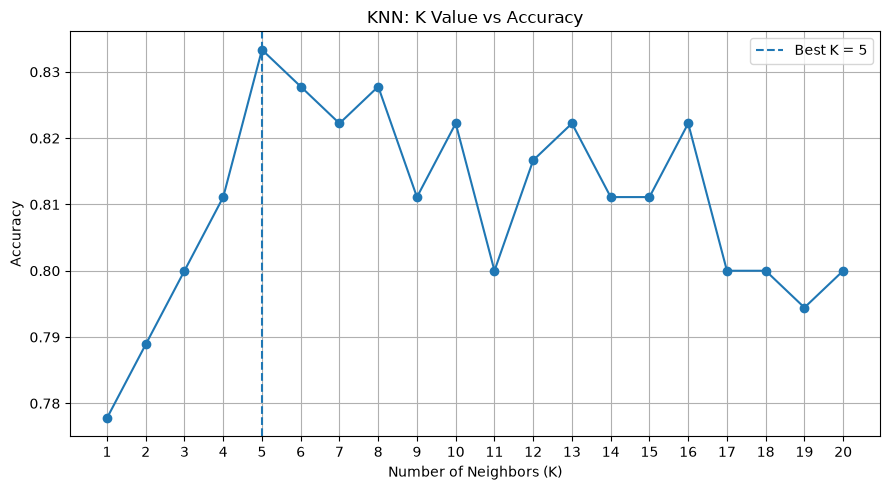

In [9]:
# Plot accuracy for different K values

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    k_accuracies,
    marker="o"
)

plt.axvline(
    best_k,
    linestyle="--",
    label=f"Best K = {best_k}"
)

plt.title("KNN: K Value vs Accuracy")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.xticks(list(k_values))
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [10]:
# Create final KNN model using selected K

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k))
])

# Train model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully.")
print("Selected K:", best_k)

KNN model trained successfully.
Selected K: 5


In [11]:
# Generate class and probability predictions

y_pred = knn_model.predict(X_test)

y_prob = knn_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 probabilities:")
print(np.round(y_prob[:10], 4))

Predictions generated successfully.

First 10 predictions:
[1 0 1 1 0 1 0 0 0 1]

First 10 probabilities:
[0.8 0.  1.  0.6 0.2 1.  0.  0.4 0.2 0.8]


In [12]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

knn_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(knn_results.round(4))

,Metric,Score
0,Accuracy,0.8333
1,Precision,0.8286
2,Recall,0.8788
3,F1 Score,0.8529
4,ROC-AUC,0.8897


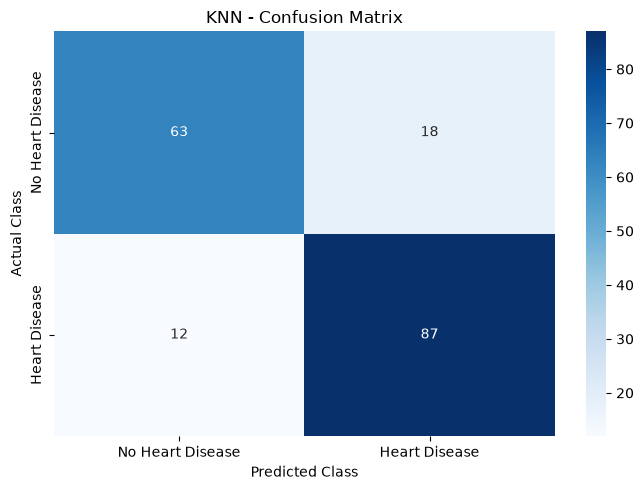


Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.84      0.78      0.81        81
   Heart Disease       0.83      0.88      0.85        99

        accuracy                           0.83       180
       macro avg       0.83      0.83      0.83       180
    weighted avg       0.83      0.83      0.83       180



In [13]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Heart Disease", "Heart Disease"],
    yticklabels=["No Heart Disease", "Heart Disease"]
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

# Classification report

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Heart Disease", "Heart Disease"],
        zero_division=0
    )
)

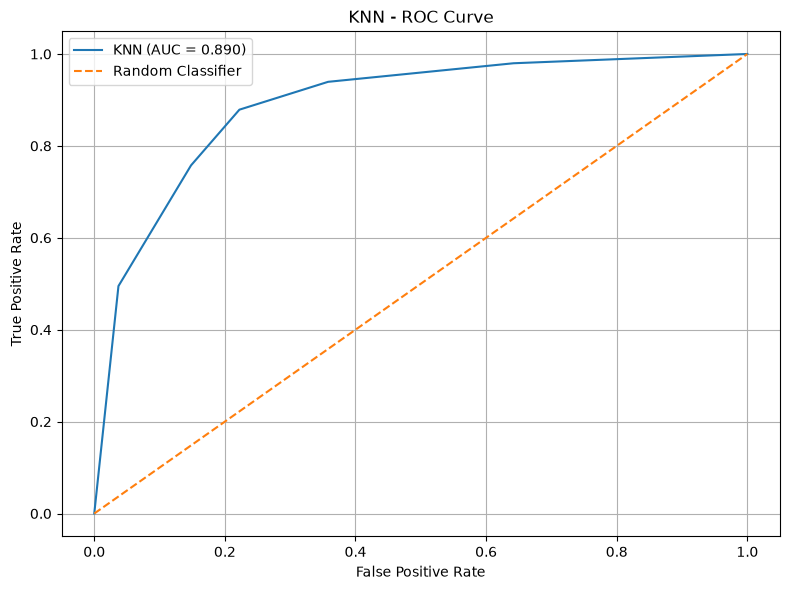

In [14]:
# ROC Curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"KNN (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN - ROC Curve")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [15]:
# Perform 5-fold stratified cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    knn_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("KNN 5-Fold Cross-Validation")
print("===========================")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV Accuracy:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

print("\nFinal KNN Performance")
print("=====================")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

KNN 5-Fold Cross-Validation
Fold 1: 0.8000
Fold 2: 0.8000
Fold 3: 0.7278
Fold 4: 0.7833
Fold 5: 0.7444

Mean CV Accuracy: 0.7711
Standard Deviation: 0.0297

Final KNN Performance
Accuracy : 0.8333
Precision: 0.8286
Recall   : 0.8788
F1 Score : 0.8529
ROC-AUC  : 0.8897
